In [ ]:
from google.colab import drive
import os


# Mount drive and set working directory
drive.mount('/content/drive')
path = '/content/drive/My Drive/PFE'
os.chdir(path)

Mounted at /content/drive


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3658 entries, 20724 to 24381
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    3658 non-null   object 
 1   Close   3658 non-null   float64
 2   High    3658 non-null   float64
 3   Low     3658 non-null   float64
 4   Open    3658 non-null   float64
 5   Volume  3658 non-null   int64  
dtypes: float64(4), int64(1), object(1)
memory usage: 171.6+ KB
None
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3658 entries, 2010-07-13 to 2025-01-24
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   3658 non-null   float64
 1   High    3658 non-null   float64
 2   Low     3658 non-null   float64
 3   Open    3658 non-null   float64
 4   Volume  3658 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 171.5 KB
None


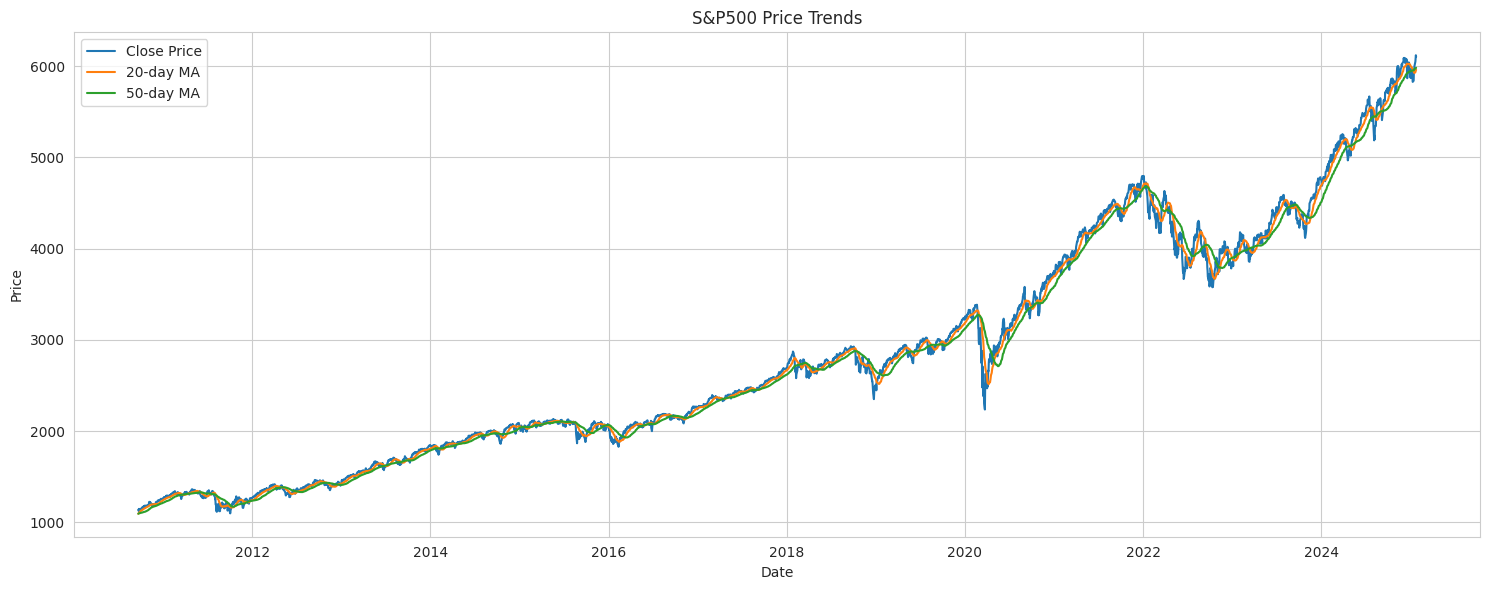

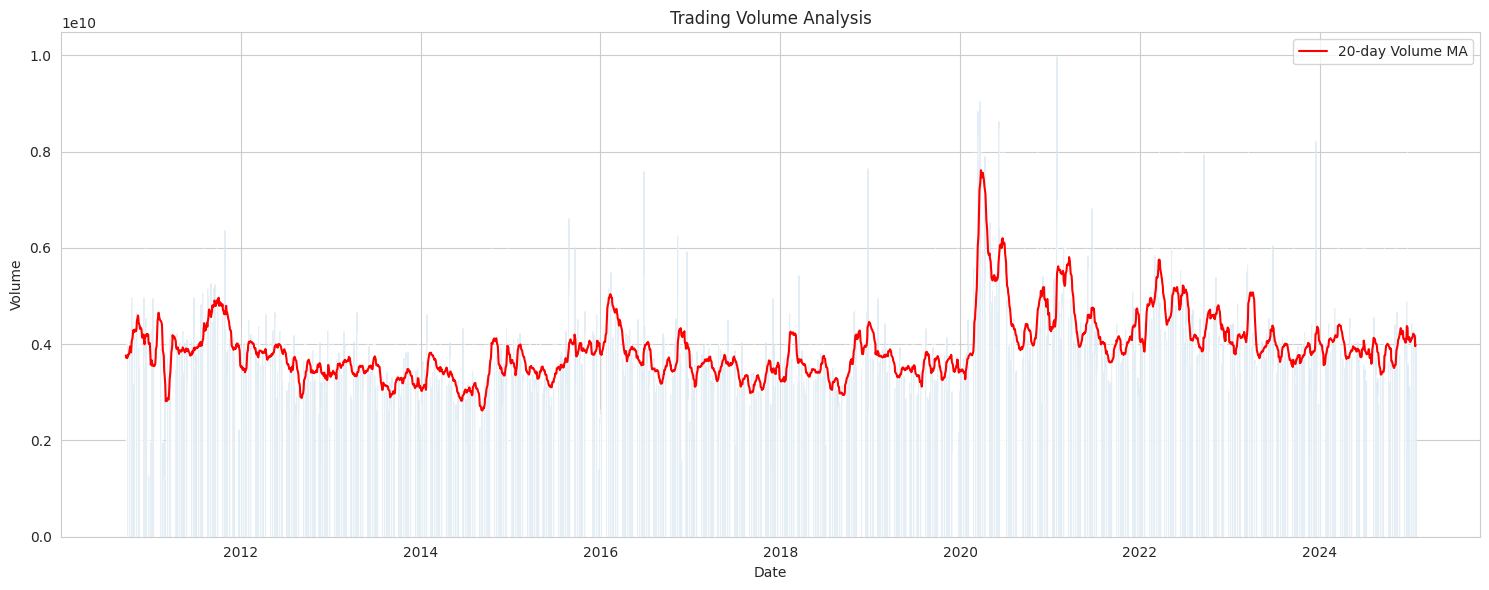

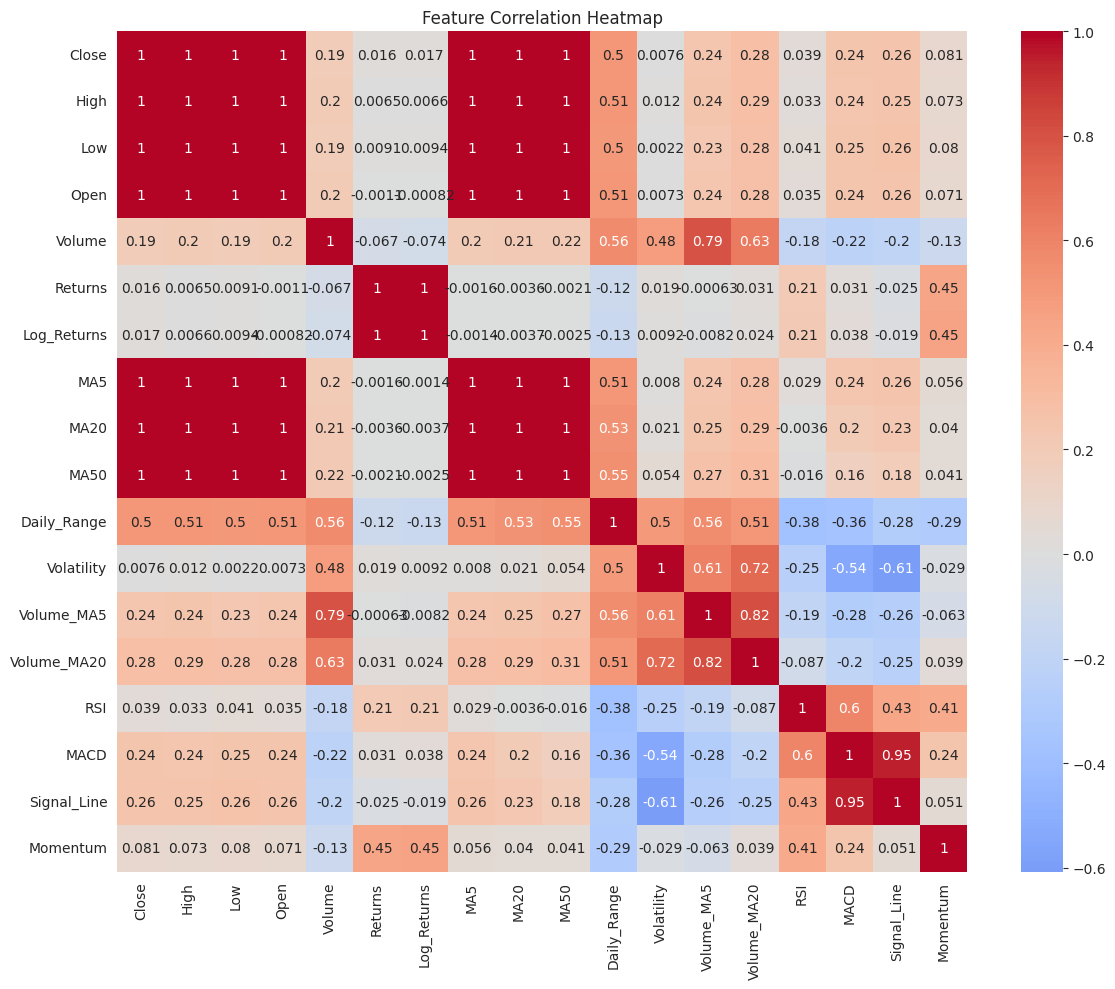

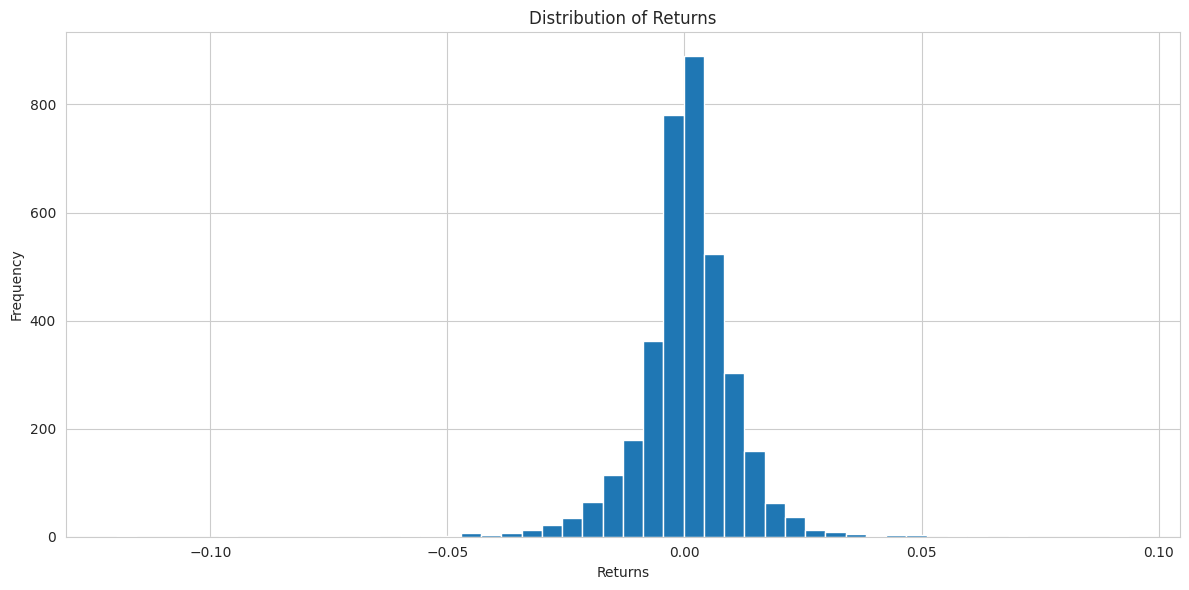

Data shape: (3609, 18)

Train set shape: (2526, 18)
Validation set shape: (541, 18)
Test set shape: (542, 18)


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import RobustScaler, MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
sns.set_style("whitegrid")

# Read and preprocess the data
df = pd.read_csv('cleaned_s&p.csv')
n = len(df)
df = df.iloc[int(0.85*n):]
print(df.info())
# Convert date to datetime
df['Date'] = pd.to_datetime(df['Date'])

# Convert other columns to numeric
numeric_columns = ['Open', 'High', 'Low', 'Close', 'Volume']
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Set date as index
df.set_index('Date', inplace=True)

# Sort index
df.sort_index(inplace=True)

print(df.info())
# Feature Engineering
# Price-based features
df['Returns'] = df['Close'].pct_change()
df['Log_Returns'] = np.log(df['Close']/df['Close'].shift(1))

# Moving averages
df['MA5'] = df['Close'].rolling(window=5).mean()
df['MA20'] = df['Close'].rolling(window=20).mean()
df['MA50'] = df['Close'].rolling(window=50).mean()

# Volatility
df['Daily_Range'] = df['High'] - df['Low']
df['Volatility'] = df['Returns'].rolling(window=20).std()

# Volume features
df['Volume_MA5'] = df['Volume'].rolling(window=5).mean()
df['Volume_MA20'] = df['Volume'].rolling(window=20).mean()

# Technical indicators
# RSI
delta = df['Close'].diff()
gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
rs = gain / loss
df['RSI'] = 100 - (100 / (1 + rs))

# MACD
exp1 = df['Close'].ewm(span=12, adjust=False).mean()
exp2 = df['Close'].ewm(span=26, adjust=False).mean()
df['MACD'] = exp1 - exp2
df['Signal_Line'] = df['MACD'].ewm(span=9, adjust=False).mean()

# Price momentum
df['Momentum'] = df['Close'] - df['Close'].shift(4)

# Drop null values
df.dropna(inplace=True)

# Scale the features
# Separate scalers for different types of features
price_scaler = MinMaxScaler()
vol_scaler = RobustScaler()

# Price-based features
price_features = ['Open', 'High', 'Low', 'Close', 'MA5', 'MA20', 'MA50']
df_scaled = df.copy()
df_scaled[price_features] = price_scaler.fit_transform(df[price_features])

# Volume and volatility features
vol_features = ['Volume', 'Volume_MA5', 'Volume_MA20', 'Volatility']
df_scaled[vol_features] = vol_scaler.fit_transform(df[vol_features])



# 1. Price trends
plt.figure(figsize=(15, 6))
plt.plot(df.index, df['Close'], label='Close Price')
plt.plot(df.index, df['MA20'], label='20-day MA')
plt.plot(df.index, df['MA50'], label='50-day MA')
plt.title('S&P500 Price Trends')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.tight_layout()
plt.show()

# 2. Volume analysis
plt.figure(figsize=(15, 6))
plt.bar(df.index, df['Volume'], alpha=0.5)
plt.plot(df.index, df['Volume_MA20'], color='red', label='20-day Volume MA')
plt.title('Trading Volume Analysis')
plt.xlabel('Date')
plt.ylabel('Volume')
plt.legend()
plt.tight_layout()
plt.show()

# 3. Correlation heatmap
plt.figure(figsize=(12, 10))
correlation = df.select_dtypes(include=[np.number]).corr()
sns.heatmap(correlation, annot=True, cmap='coolwarm', center=0)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

# 4. Returns distribution
plt.figure(figsize=(12, 6))
df['Returns'].hist(bins=50)
plt.title('Distribution of Returns')
plt.xlabel('Returns')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# Split the data
total_size = len(df)
train_size = 0.7
val_size = 0.15

train_end = int(total_size * train_size)
val_end = int(total_size * (train_size + val_size))

train_data = df_scaled[:train_end]
val_data = df_scaled[train_end:val_end]
test_data = df_scaled[val_end:]

print("Data shape:", df.shape)
print("\nTrain set shape:", train_data.shape)
print("Validation set shape:", val_data.shape)
print("Test set shape:", test_data.shape)

1-RNN


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - loss: 0.0023 - val_loss: 3.8214e-04
Epoch 2/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 4.2870e-04 - val_loss: 3.6960e-04
Epoch 3/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 3.7240e-04 - val_loss: 3.5745e-04
Epoch 4/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 2.2880e-04 - val_loss: 2.1183e-04
Epoch 5/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 2.0798e-04 - val_loss: 3.6765e-04
Epoch 6/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.5749e-04 - val_loss: 1.6787e-04
Epoch 7/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 1.6254e-04 - val_loss: 1.8149e-04
Epoch 8/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 1.3477e-04 - val_loss: 1.6981e-04
Epoch 9/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 1.3780e-04 - val_loss: 1.4329e-04
Epoch 10/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 1.2206e-04 - val_loss: 2.5740e-04
Epoch 11/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 1

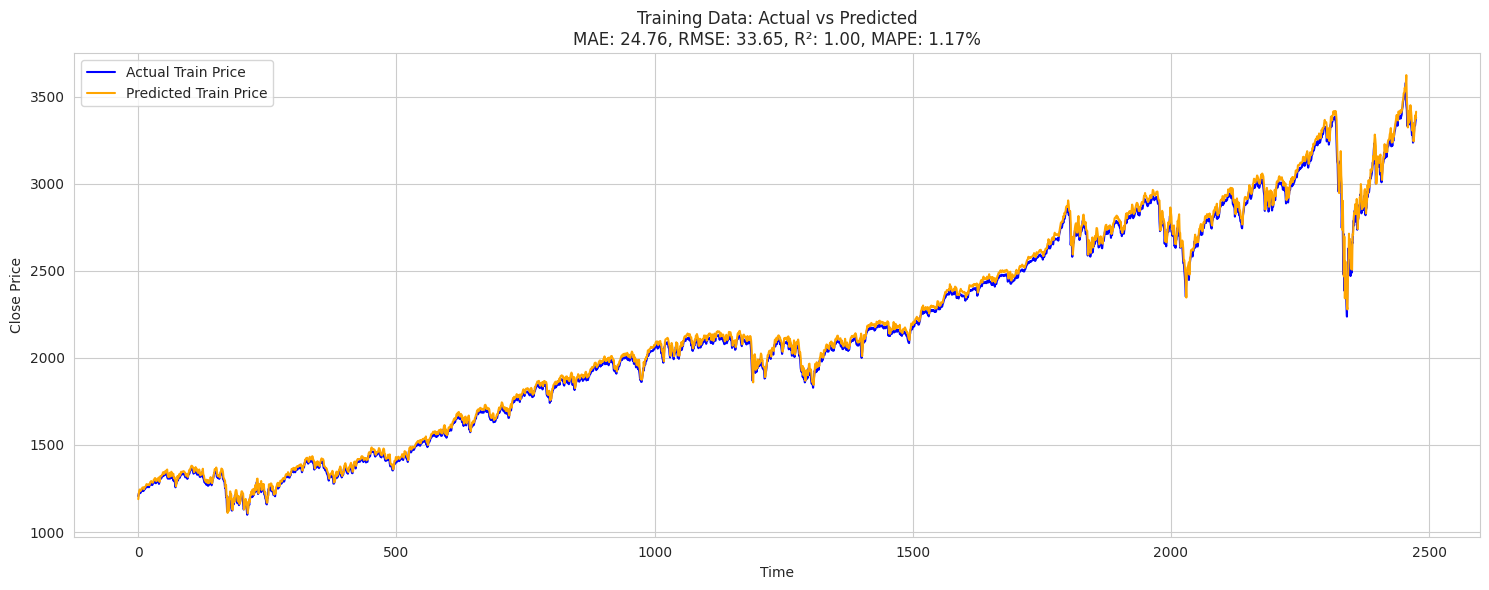

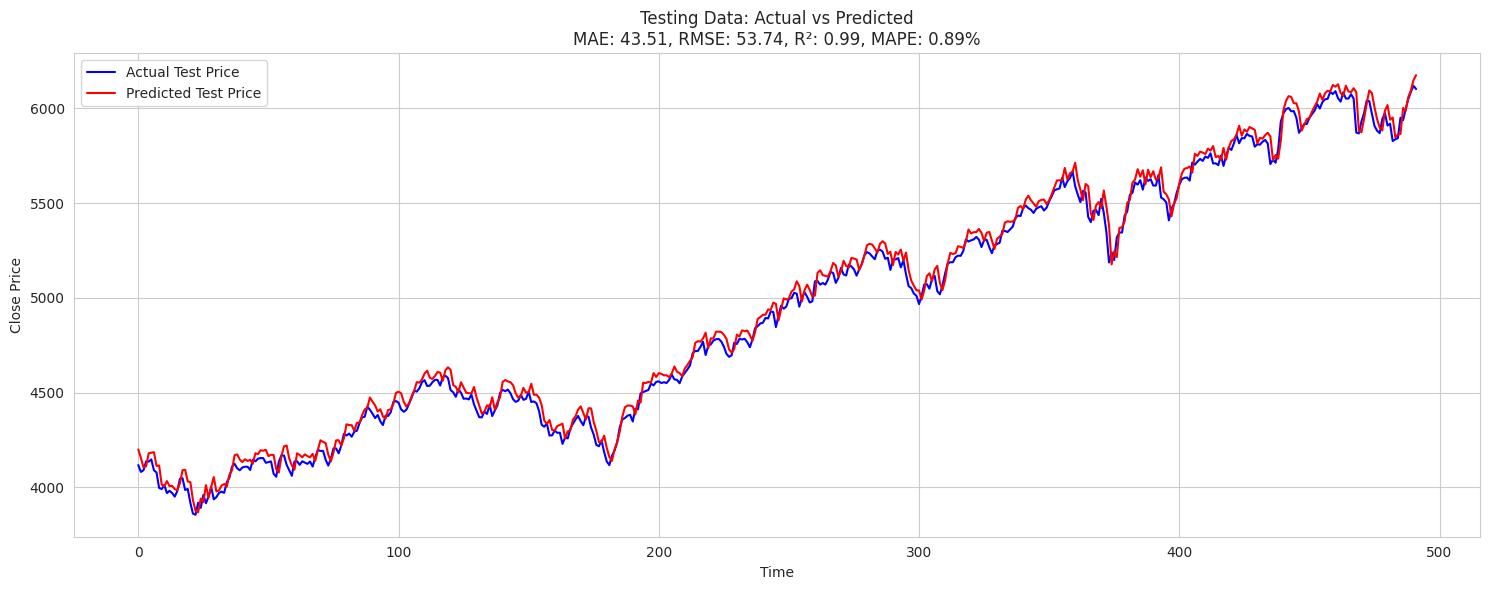

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Dropout
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import numpy as np

# --- Prepare Data for RNN ---
sequence_length = 50  # Number of past days to use for prediction
target_column = 'Close'

# Prepare sequences and labels for training
X = []
y = []

for i in range(sequence_length, len(train_data)):
    X.append(train_data[target_column].values[i-sequence_length:i])
    y.append(train_data[target_column].values[i])

X = np.array(X)
y = np.array(y)

# Reshape X for RNN (samples, time steps, features)
X = X.reshape((X.shape[0], X.shape[1], 1))

# --- Define RNN Model ---
rnn_model = Sequential([
    SimpleRNN(50, activation='tanh', input_shape=(X.shape[1], X.shape[2])),
    Dropout(0.2),
    Dense(1)  # Output layer for predicting Close price
])

# Compile Model
rnn_model.compile(optimizer='adam', loss='mse')

# Train Model
history = rnn_model.fit(X, y, epochs=50, batch_size=8, validation_split=0.1, verbose=1)

# --- Prepare Test Data ---
X_test = []
y_test = []

for i in range(sequence_length, len(test_data)):
    X_test.append(test_data[target_column].values[i-sequence_length:i])
    y_test.append(test_data[target_column].values[i])

X_test = np.array(X_test)
y_test = np.array(y_test)

X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# --- Make Predictions ---
# Train predictions
train_predicted = rnn_model.predict(X)

# Test predictions
test_predicted = rnn_model.predict(X_test)

# --- Extract scaling parameters for inverse transformation ---
close_min = df['Close'].min()
close_max = df['Close'].max()

# Inverse transform train and test predictions
train_predicted_prices = (train_predicted * (close_max - close_min)) + close_min
test_predicted_prices = (test_predicted * (close_max - close_min)) + close_min

# Inverse transform actual values for train and test sets
actual_train_prices = (y.reshape(-1, 1) * (close_max - close_min)) + close_min
actual_test_prices = (y_test.reshape(-1, 1) * (close_max - close_min)) + close_min

# --- Calculate Metrics ---
# Train metrics
train_mae = mean_absolute_error(actual_train_prices, train_predicted_prices)
train_rmse = np.sqrt(mean_squared_error(actual_train_prices, train_predicted_prices))
train_r2 = r2_score(actual_train_prices, train_predicted_prices)
train_mape = np.mean(np.abs((actual_train_prices - train_predicted_prices) / actual_train_prices)) * 100

# Test metrics
test_mae = mean_absolute_error(actual_test_prices, test_predicted_prices)
test_rmse = np.sqrt(mean_squared_error(actual_test_prices, test_predicted_prices))
test_r2 = r2_score(actual_test_prices, test_predicted_prices)
test_mape = np.mean(np.abs((actual_test_prices - test_predicted_prices) / actual_test_prices)) * 100

print(f'Train MAE: {train_mae}, RMSE: {train_rmse}, R²: {train_r2}')
print(f'Test MAE: {test_mae}, RMSE: {test_rmse}, R²: {test_r2}')

# --- Visualization ---
# Plot Train Predictions
plt.figure(figsize=(15, 6))
plt.plot(actual_train_prices, label='Actual Train Price', color='blue')
plt.plot(train_predicted_prices, label='Predicted Train Price', color='orange')
plt.title(f'Training Data: Actual vs Predicted\nMAE: {train_mae:.2f}, RMSE: {train_rmse:.2f}, R²: {train_r2:.2f}, MAPE: {train_mape:.2f}%')
plt.xlabel('Time')
plt.ylabel('Close Price')
plt.legend()
plt.tight_layout()
plt.show()

# Plot Test Predictions
plt.figure(figsize=(15, 6))
plt.plot(actual_test_prices, label='Actual Test Price', color='blue')
plt.plot(test_predicted_prices, label='Predicted Test Price', color='red')
plt.title(f'Testing Data: Actual vs Predicted\nMAE: {test_mae:.2f}, RMSE: {test_rmse:.2f}, R²: {test_r2:.2f}, MAPE: {test_mape:.2f}%')
plt.xlabel('Time')
plt.ylabel('Close Price')
plt.legend()
plt.tight_layout()
plt.show()


2-LSTM


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - loss: 0.0038 - val_loss: 0.0013
Epoch 2/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 4.3796e-04 - val_loss: 5.6763e-04
Epoch 3/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 3.2385e-04 - val_loss: 8.4382e-04
Epoch 4/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 2.8985e-04 - val_loss: 6.2389e-04
Epoch 5/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 2.3802e-04 - val_loss: 5.9193e-04
Epoch 6/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 2.0214e-04 - val_loss: 5.5389e-04
Epoch 7/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 1.9479e-04 - val_loss: 3.8022e-04
Epoch 8/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 1.8582e-04 - val_loss: 3.2597e-04
Epoch 9/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 1.6854e-04 - val_loss: 6.9107e-04
Epoch 10/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 1.5409e-04 - val_loss: 3.6223e-04
Epoch 11/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 1.8

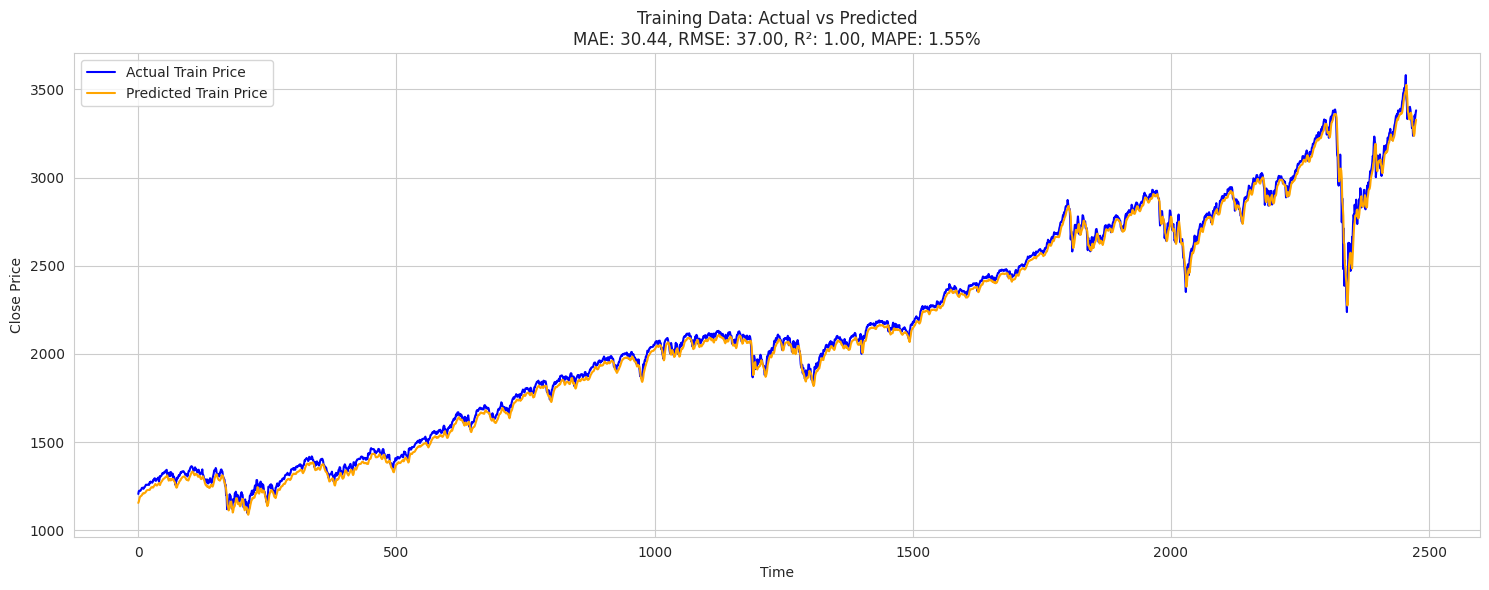

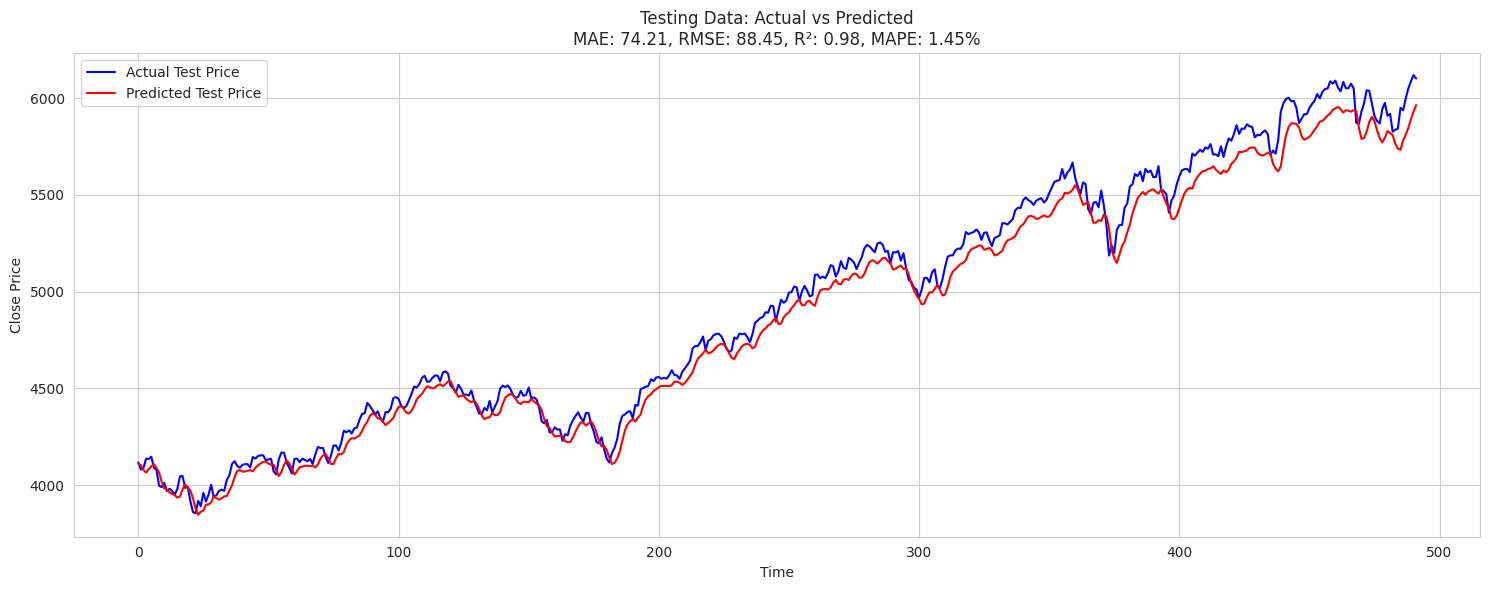

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import numpy as np

# --- Prepare Data for LSTM ---
sequence_length = 50  # Number of past days to use for prediction
target_column = 'Close'

# Prepare sequences and labels for training
X = []
y = []

for i in range(sequence_length, len(train_data)):
    X.append(train_data[target_column].values[i-sequence_length:i])
    y.append(train_data[target_column].values[i])

X = np.array(X)
y = np.array(y)

# Reshape X for LSTM (samples, time steps, features)
X = X.reshape((X.shape[0], X.shape[1], 1))

# --- Define LSTM Model ---
lstm_model = Sequential([
    LSTM(100, activation='tanh', return_sequences=True, input_shape=(X.shape[1], X.shape[2])),
    Dropout(0.2),
    LSTM(50, activation='tanh'),
    Dropout(0.2),
    Dense(1)  # Output layer
])

# Compile Model
lstm_model.compile(optimizer='adam', loss='mse')

# Train Model
history = lstm_model.fit(X, y, epochs=50, batch_size=8, validation_split=0.1, verbose=1)

# --- Prepare Test Data ---
X_test = []
y_test = []

for i in range(sequence_length, len(test_data)):
    X_test.append(test_data[target_column].values[i-sequence_length:i])
    y_test.append(test_data[target_column].values[i])

X_test = np.array(X_test)
y_test = np.array(y_test)

X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# --- Make Predictions ---
# Train predictions
train_predicted = lstm_model.predict(X)

# Test predictions
test_predicted = lstm_model.predict(X_test)

# --- Extract scaling parameters for inverse transformation ---
close_min = df['Close'].min()
close_max = df['Close'].max()

# Inverse transform train and test predictions
train_predicted_prices = (train_predicted * (close_max - close_min)) + close_min
test_predicted_prices = (test_predicted * (close_max - close_min)) + close_min

# Inverse transform actual values for train and test sets
actual_train_prices = (y.reshape(-1, 1) * (close_max - close_min)) + close_min
actual_test_prices = (y_test.reshape(-1, 1) * (close_max - close_min)) + close_min

# --- Calculate Metrics ---
# Train metrics
train_mae = mean_absolute_error(actual_train_prices, train_predicted_prices)
train_rmse = np.sqrt(mean_squared_error(actual_train_prices, train_predicted_prices))
train_r2 = r2_score(actual_train_prices, train_predicted_prices)
train_mape = np.mean(np.abs((actual_train_prices - train_predicted_prices) / actual_train_prices)) * 100

# Test metrics
test_mae = mean_absolute_error(actual_test_prices, test_predicted_prices)
test_rmse = np.sqrt(mean_squared_error(actual_test_prices, test_predicted_prices))
test_r2 = r2_score(actual_test_prices, test_predicted_prices)
test_mape = np.mean(np.abs((actual_test_prices - test_predicted_prices) / actual_test_prices)) * 100

print(f'Train MAE: {train_mae}, RMSE: {train_rmse}, R²: {train_r2}')
print(f'Test MAE: {test_mae}, RMSE: {test_rmse}, R²: {test_r2}')

# --- Visualization ---
# Plot Train Predictions
plt.figure(figsize=(15, 6))
plt.plot(actual_train_prices, label='Actual Train Price', color='blue')
plt.plot(train_predicted_prices, label='Predicted Train Price', color='orange')
plt.title(f'Training Data: Actual vs Predicted\nMAE: {train_mae:.2f}, RMSE: {train_rmse:.2f}, R²: {train_r2:.2f}, MAPE: {train_mape:.2f}%')
plt.xlabel('Time')
plt.ylabel('Close Price')
plt.legend()
plt.tight_layout()
plt.show()

# Plot Test Predictions
plt.figure(figsize=(15, 6))
plt.plot(actual_test_prices, label='Actual Test Price', color='blue')
plt.plot(test_predicted_prices, label='Predicted Test Price', color='red')
plt.title(f'Testing Data: Actual vs Predicted\nMAE: {test_mae:.2f}, RMSE: {test_rmse:.2f}, R²: {test_r2:.2f}, MAPE: {test_mape:.2f}%')
plt.xlabel('Time')
plt.ylabel('Close Price')
plt.legend()
plt.tight_layout()
plt.show()


3-Bi-Directional LSTM


Epoch 1/50


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


279/279 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - loss: 0.0026 - val_loss: 0.0016
Epoch 2/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 6.0074e-04 - val_loss: 0.0013
Epoch 3/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - loss: 4.8189e-04 - val_loss: 0.0010
Epoch 4/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 3.4773e-04 - val_loss: 7.9718e-04
Epoch 5/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 3.0180e-04 - val_loss: 7.9178e-04
Epoch 6/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - loss: 3.0248e-04 - val_loss: 5.9530e-04
Epoch 7/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - loss: 2.5353e-04 - val_loss: 7.5380e-04
Epoch 8/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 2.5222e-04 - val_loss: 5.7420e-04
Epoch 9/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - loss: 2.2765e-04 - val_loss: 5.2105e-04
Epoch 10/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 2.3934e-04 - val_loss: 7.8556e-04
Epoch 11/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 2.2550e-04 - v

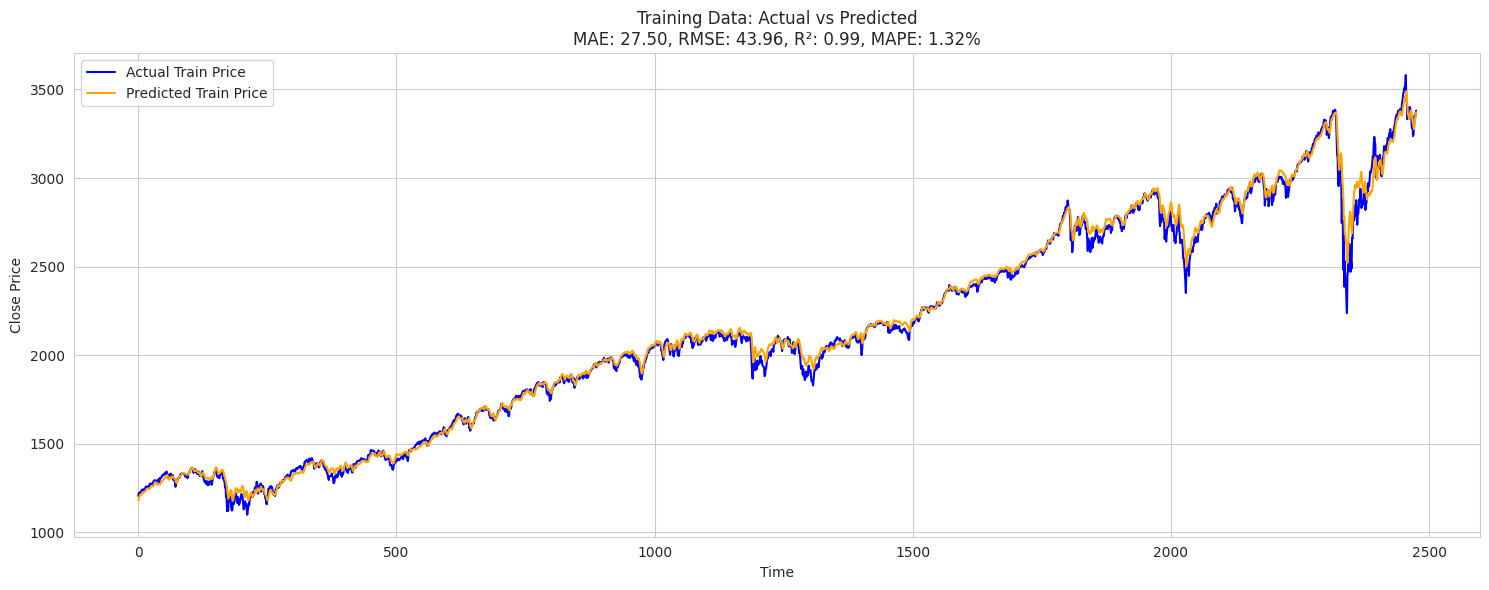

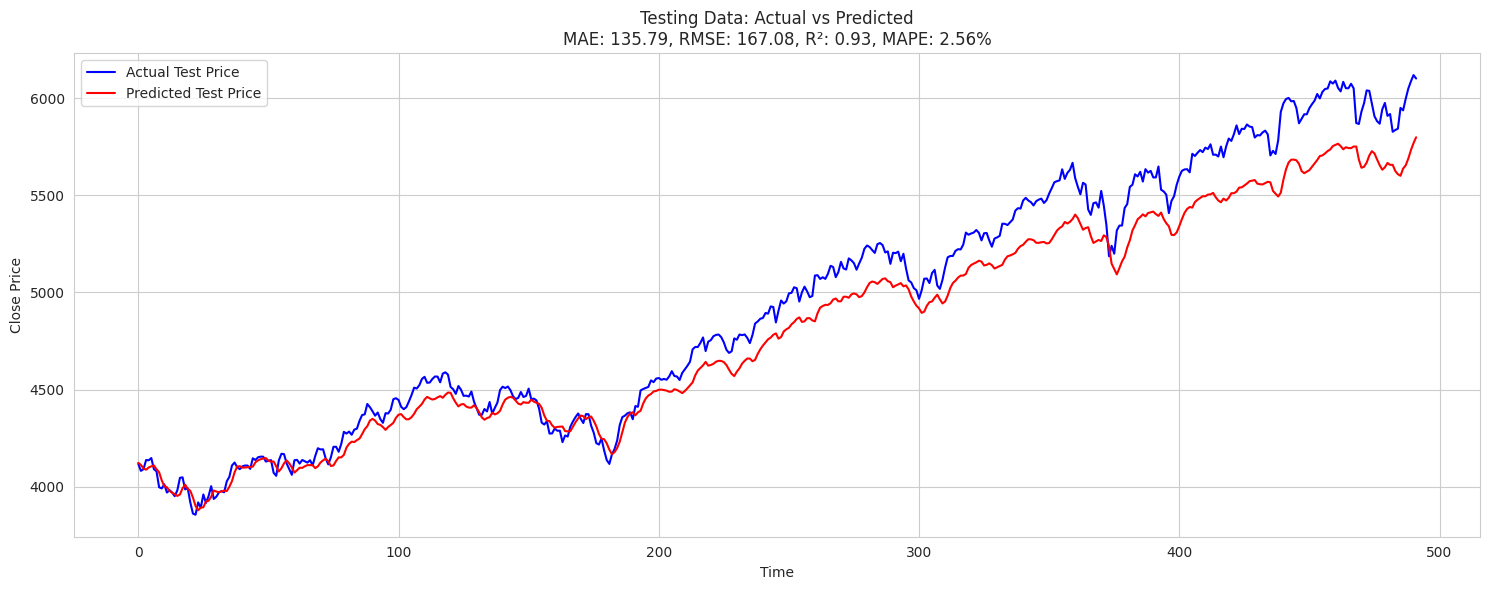

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Bidirectional, LSTM, Dense, Dropout
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import numpy as np

# --- Prepare Data for Bidirectional LSTM ---
sequence_length = 50  # Number of past days to use for prediction
target_column = 'Close'

# Prepare sequences and labels for training
X = []
y = []

for i in range(sequence_length, len(train_data)):
    X.append(train_data[target_column].values[i-sequence_length:i])
    y.append(train_data[target_column].values[i])

X = np.array(X)
y = np.array(y)

# Reshape X for LSTM (samples, time steps, features)
X = X.reshape((X.shape[0], X.shape[1], 1))

# Prepare test data
X_test = []
y_test = []

for i in range(sequence_length, len(test_data)):
    X_test.append(test_data[target_column].values[i-sequence_length:i])
    y_test.append(test_data[target_column].values[i])

X_test = np.array(X_test)
y_test = np.array(y_test)

X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# --- Define Bidirectional LSTM Model ---
bi_lstm_model = Sequential([
    Bidirectional(LSTM(100, activation='tanh', return_sequences=True, input_shape=(X.shape[1], X.shape[2]))),
    Dropout(0.4),
    Bidirectional(LSTM(50, activation='tanh')),
    Dropout(0.4),
    Dense(1)  # Output layer
])

# Compile Model
bi_lstm_model.compile(optimizer='adam', loss='mse')

# Train Model
history = bi_lstm_model.fit(X, y, epochs=50, batch_size=8, validation_split=0.1, verbose=1)

# --- Make Predictions ---
# Train predictions
train_predicted = bi_lstm_model.predict(X)

# Test predictions
test_predicted = bi_lstm_model.predict(X_test)

# --- Extract scaling parameters for inverse transformation ---
close_min = df['Close'].min()
close_max = df['Close'].max()

# Inverse transform train and test predictions
train_predicted_prices = (train_predicted * (close_max - close_min)) + close_min
test_predicted_prices = (test_predicted * (close_max - close_min)) + close_min

# Inverse transform actual values for train and test sets
actual_train_prices = (y.reshape(-1, 1) * (close_max - close_min)) + close_min
actual_test_prices = (y_test.reshape(-1, 1) * (close_max - close_min)) + close_min

# --- Calculate Metrics ---
# Train metrics
train_mae = mean_absolute_error(actual_train_prices, train_predicted_prices)
train_rmse = np.sqrt(mean_squared_error(actual_train_prices, train_predicted_prices))
train_r2 = r2_score(actual_train_prices, train_predicted_prices)
train_mape = np.mean(np.abs((actual_train_prices - train_predicted_prices) / actual_train_prices)) * 100

# Test metrics
test_mae = mean_absolute_error(actual_test_prices, test_predicted_prices)
test_rmse = np.sqrt(mean_squared_error(actual_test_prices, test_predicted_prices))
test_r2 = r2_score(actual_test_prices, test_predicted_prices)
test_mape = np.mean(np.abs((actual_test_prices - test_predicted_prices) / actual_test_prices)) * 100

print(f'Train MAE: {train_mae}, RMSE: {train_rmse}, R²: {train_r2}, MAPE: {train_mape:.2f}%')
print(f'Test MAE: {test_mae}, RMSE: {test_rmse}, R²: {test_r2}, MAPE: {test_mape:.2f}%')

# --- Visualization ---
# Plot Train Predictions
plt.figure(figsize=(15, 6))
plt.plot(actual_train_prices, label='Actual Train Price', color='blue')
plt.plot(train_predicted_prices, label='Predicted Train Price', color='orange')
plt.title(f'Training Data: Actual vs Predicted\nMAE: {train_mae:.2f}, RMSE: {train_rmse:.2f}, R²: {train_r2:.2f}, MAPE: {train_mape:.2f}%')
plt.xlabel('Time')
plt.ylabel('Close Price')
plt.legend()
plt.tight_layout()
plt.show()

# Plot Test Predictions
plt.figure(figsize=(15, 6))
plt.plot(actual_test_prices, label='Actual Test Price', color='blue')
plt.plot(test_predicted_prices, label='Predicted Test Price', color='red')
plt.title(f'Testing Data: Actual vs Predicted\nMAE: {test_mae:.2f}, RMSE: {test_rmse:.2f}, R²: {test_r2:.2f}, MAPE: {test_mape:.2f}%')
plt.xlabel('Time')
plt.ylabel('Close Price')
plt.legend()
plt.tight_layout()
plt.show()


4-GRU

Epoch 1/50


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


279/279 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 0.0026 - val_loss: 3.1376e-04
Epoch 2/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 2.1884e-04 - val_loss: 3.0172e-04
Epoch 3/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 1.8956e-04 - val_loss: 5.8320e-04
Epoch 4/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 1.8759e-04 - val_loss: 6.2026e-04
Epoch 5/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 1.7170e-04 - val_loss: 1.9501e-04
Epoch 6/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 1.3997e-04 - val_loss: 2.9821e-04
Epoch 7/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 1.3866e-04 - val_loss: 1.8613e-04
Epoch 8/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 1.1910e-04 - val_loss: 2.0331e-04
Epoch 9/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 1.3129e-04 - val_loss: 1.5398e-04
Epoch 10/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 1.0484e-04 - val_loss: 2.9835e-04
Epoch 11/50
279/279 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 1.2294e-04

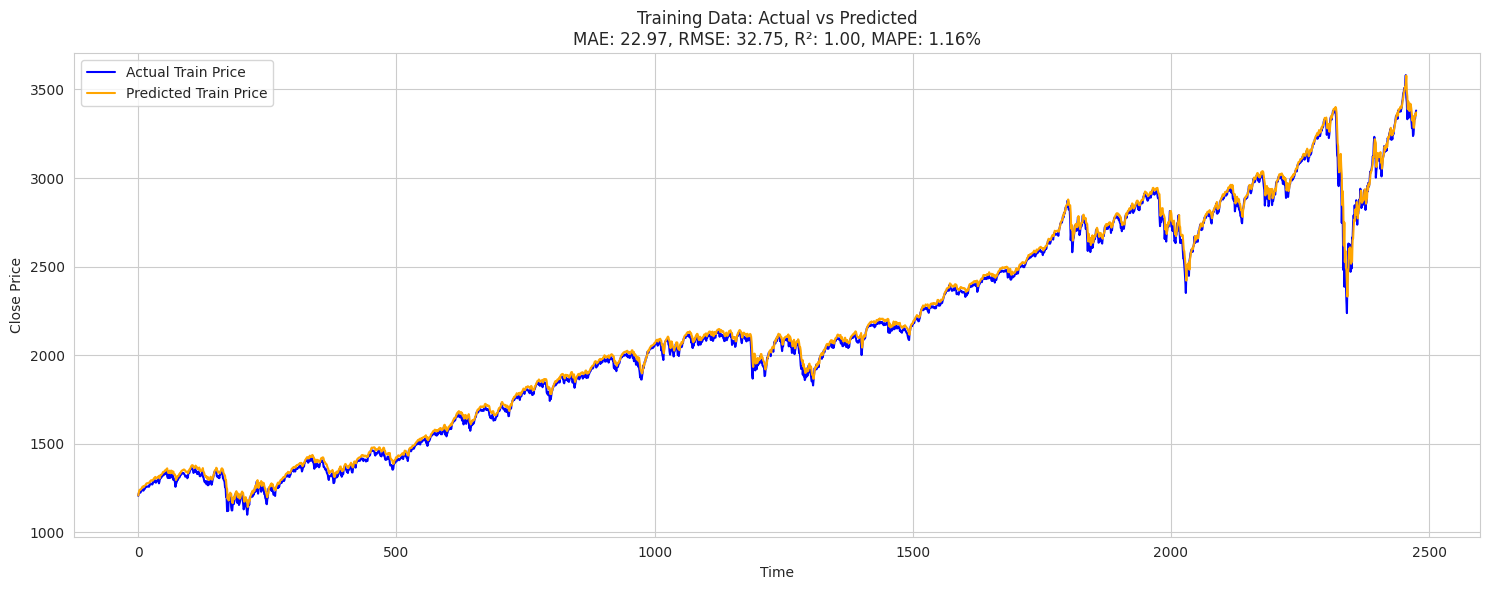

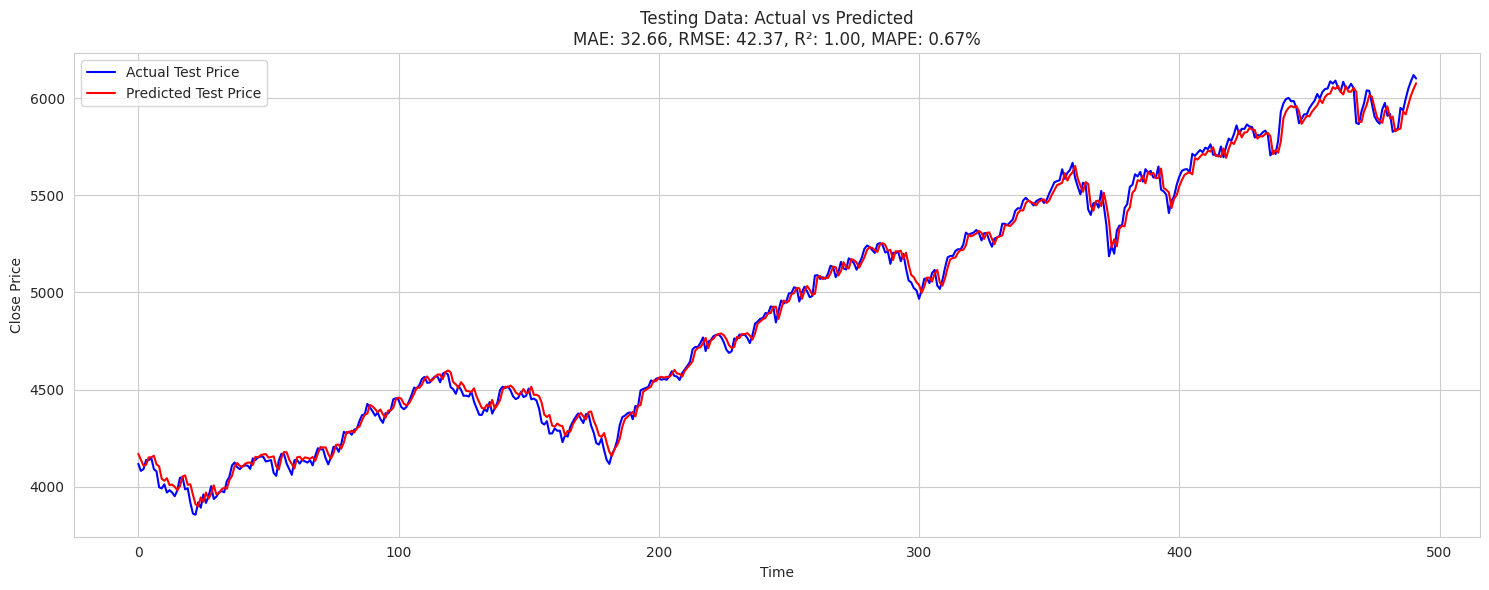

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Dropout
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import numpy as np

# --- Prepare Data for GRU ---
sequence_length = 50  # Number of past days to use for prediction
target_column = 'Close'

# Prepare sequences and labels for training
X = []
y = []

for i in range(sequence_length, len(train_data)):
    X.append(train_data[target_column].values[i-sequence_length:i])
    y.append(train_data[target_column].values[i])

X = np.array(X)
y = np.array(y)

# Reshape X for GRU (samples, time steps, features)
X = X.reshape((X.shape[0], X.shape[1], 1))

# Prepare test data
X_test = []
y_test = []

for i in range(sequence_length, len(test_data)):
    X_test.append(test_data[target_column].values[i-sequence_length:i])
    y_test.append(test_data[target_column].values[i])

X_test = np.array(X_test)
y_test = np.array(y_test)

X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# --- Define GRU Model ---
gru_model = Sequential([
    GRU(100, activation='tanh', return_sequences=True, input_shape=(X.shape[1], X.shape[2])),
    Dropout(0.2),
    GRU(50, activation='tanh'),
    Dropout(0.1),
    Dense(1)  # Output layer
])

# Compile Model
gru_model.compile(optimizer='adam', loss=tf.keras.losses.MeanSquaredError())

# Train Model
history = gru_model.fit(X, y, epochs=50, batch_size=8, validation_split=0.1, verbose=1)

# --- Make Predictions ---
# Train predictions
train_predicted = gru_model.predict(X)


test_predicted = gru_model.predict(X_test)


close_min = df['Close'].min()
close_max = df['Close'].max()


train_predicted_prices = (train_predicted * (close_max - close_min)) + close_min
test_predicted_prices = (test_predicted * (close_max - close_min)) + close_min


actual_train_prices = (y.reshape(-1, 1) * (close_max - close_min)) + close_min
actual_test_prices = (y_test.reshape(-1, 1) * (close_max - close_min)) + close_min

# --- Predict Next 25 Days ---
def predict_next_days(gru_model, recent_data, num_days, sequence_length):
    predictions = []
    current_sequence = recent_data[-sequence_length:].reshape(1, sequence_length, 1)

    for _ in range(num_days):
        next_prediction = gru_model.predict(current_sequence)[0][0]
        predictions.append(next_prediction)
        current_sequence = np.append(current_sequence[:, 1:, :], [[[next_prediction]]], axis=1)

    # Inverse transform predictions
    predictions_actual = [(p * (close_max - close_min)) + close_min for p in predictions]
    return predictions_actual

# Get the most recent data from the test dataset
recent_data = test_data[target_column].values

# Predict the next 25 days
future_predictions = predict_next_days(gru_model, recent_data, 2, sequence_length)
print("Predicted Close Prices for the Next 2 Days:", future_predictions)

# --- Calculate Metrics ---
# Train metrics
train_mae = mean_absolute_error(actual_train_prices, train_predicted_prices)
train_rmse = np.sqrt(mean_squared_error(actual_train_prices, train_predicted_prices))
train_r2 = r2_score(actual_train_prices, train_predicted_prices)
train_mape = np.mean(np.abs((actual_train_prices - train_predicted_prices) / actual_train_prices)) * 100

# Test metrics
test_mae = mean_absolute_error(actual_test_prices, test_predicted_prices)
test_rmse = np.sqrt(mean_squared_error(actual_test_prices, test_predicted_prices))
test_r2 = r2_score(actual_test_prices, test_predicted_prices)
test_mape = np.mean(np.abs((actual_test_prices - test_predicted_prices) / actual_test_prices)) * 100

print(f'Train MAE: {train_mae}, RMSE: {train_rmse}, R²: {train_r2}, MAPE: {train_mape:.2f}%')
print(f'Test MAE: {test_mae}, RMSE: {test_rmse}, R²: {test_r2}, MAPE: {test_mape:.2f}%')

# --- Visualization ---
# Plot Train Predictions
plt.figure(figsize=(15, 6))
plt.plot(actual_train_prices, label='Actual Train Price', color='blue')
plt.plot(train_predicted_prices, label='Predicted Train Price', color='orange')
plt.title(f'Training Data: Actual vs Predicted\nMAE: {train_mae:.2f}, RMSE: {train_rmse:.2f}, R²: {train_r2:.2f}, MAPE: {train_mape:.2f}%')
plt.xlabel('Time')
plt.ylabel('Close Price')
plt.legend()
plt.tight_layout()
plt.show()

# Plot Test Predictions
plt.figure(figsize=(15, 6))
plt.plot(actual_test_prices, label='Actual Test Price', color='blue')
plt.plot(test_predicted_prices, label='Predicted Test Price', color='red')
plt.title(f'Testing Data: Actual vs Predicted\nMAE: {test_mae:.2f}, RMSE: {test_rmse:.2f}, R²: {test_r2:.2f}, MAPE: {test_mape:.2f}%')
plt.xlabel('Time')
plt.ylabel('Close Price')
plt.legend()
plt.tight_layout()
plt.show()
gru_model.save("gru_model.h5")


In [1]:
import yfinance as yf

data = yf.download('^GSPC', period="1mo")
print(data)


YF.download() has changed argument auto_adjust default to True


[*********************100%***********************]  1 of 1 completed

Price             Close         High          Low         Open      Volume
Ticker            ^GSPC        ^GSPC        ^GSPC        ^GSPC       ^GSPC
Date                                                                      
2025-03-10  5614.560059  5705.370117  5564.020020  5705.370117  6409370000
2025-03-11  5572.069824  5636.299805  5528.410156  5603.649902  6221240000
2025-03-12  5599.299805  5642.189941  5546.089844  5624.839844  5219830000
2025-03-13  5521.520020  5597.779785  5504.649902  5594.450195  5018980000
2025-03-14  5638.939941  5645.270020  5563.850098  5563.850098  4863180000
2025-03-17  5675.120117  5703.520020  5631.120117  5635.600098  5031770000
2025-03-18  5614.660156  5654.529785  5597.759766  5654.529785  4666270000
2025-03-19  5675.290039  5715.330078  5622.200195  5632.370117  4660090000
2025-03-20  5662.890137  5711.149902  5632.330078  5646.919922  4678420000
2025-03-21  5667.560059  5670.839844  5603.100098  5630.729980  9367460000
2025-03-24  5767.569824  